# 04 - Predict Models

## objective 

This step aims to analyze the séries temporais of the revenue monthly throughout of the years construído in the notebook `03_Temporal_Analysis.iptnb`, in order to support a building of different models of forecasting.

thus, busca-if build different models the: Naive Forecast, Holt-Winters, ARIMA and SARIMA. the motivo pela escolha destes models are:

At the end of this step will be possible understand a better estratégia and abordagem for a creation of the models of forecasting. therefore, queremos:

- Definir a variable *target* of the model;
- Descobrir possible inconsistencies in the série temporal of revenue;
- Descobrir a presence of trend and seasonality in the date, whether additive or multiplicative.

In [1]:
from pathlib import Path
import pandas as pd

# Caminho of the projeto
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "interm"

# Carregamento of the date
csv_file = DATA_PATH / "data_3.csv"
banco = pd.read_csv(csv_file)

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Parâmetros of estilo of the Gráfico based in the manual of the MBA
plt.rcParams.update({

    # font
    "font.family": "Arial",
    "font.size": 11,

    # background
    "figure.facecolor": "white",
    "axes.facecolor": "white",

    # without grid
    "axes.grid": False,

    # without title
    "axes.titlesize": 0,

    # axes
    "axes.edgecolor": "black",
    "axes.linewidth": 1.5,

    # color of the textos
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    # size of the titles of the axes
    "axes.labelsize": 11

})

In [4]:
def build_monthly_faturamento_total(df, start='2017-01-01', end='2025-08-01'):
    """Retorna pd.DataFrame (index datetime início de mês) com coluna 'valor_total' somada por mês contínuo."""
    # if columns 'year' and 'mes' existirem, use-the; caso contrário extraia of date_sale
    if 'ano' in df.columns and 'mes' in df.columns:
        tmp = (
            df.groupby(['ano', 'mes'])['valor_total']
            .sum()
            .reset_index()
        )
        tmp['date'] = pd.to_datetime(dict(year=tmp['ano'], month=tmp['mes'], day=1))
    else:
        tmp = (
            df.groupby([df['data_venda'].dt.year, df['data_venda'].dt.month])['valor_total']
            .sum()
            .reset_index(name='valor_total')
        )
        tmp.columns = ['ano', 'mes', 'valor_total']
        tmp['date'] = pd.to_datetime(dict(year=tmp['ano'], month=tmp['mes'], day=1))
    monthly = tmp.sort_values('date').set_index('date')[['valor_total']]
    idx = pd.date_range(start=start, end=end, freq='MS')
    monthly = monthly.reindex(idx, fill_value=0)
    monthly.index.name = 'date'
    return monthly

In [5]:
def plot_with_style(
    data,
    kind='line',                 # 'line' or 'bar'
    x_label='',
    y_label='',
    title='',
    xticks=None,                 # ticks personalizados
    xtlabels=None,               # labels personalizados
    rotate_xticks=0,
    figsize=(12, 6),
    marker='o',
    linewidth=2,
    colors=None,
    linestyles=None,
    xlim=None,                   # ex.: ('2017-01-01', '2026-01-01')
    year_ticks=True,             # ticks annual automáticos
    vline=None,                  # ex.: test.index[0]
    vline_label=None
):

    # ---------------------------------------------------------
    # Validação
    # ---------------------------------------------------------

    if not isinstance(data, (pd.Series, pd.DataFrame)):
        raise ValueError(
            'date must be pd.Series or pd.DataFrame'
        )

    if kind not in ['line', 'bar']:
        raise ValueError(
            "kind must be 'line' or 'bar'"
        )

    # ---------------------------------------------------------
    # creation of the figura
    # ---------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    # ---------------------------------------------------------
    # Gráfico of Series
    # ---------------------------------------------------------

    if isinstance(data, pd.Series):

        label = data.name if data.name is not None else 'Série'

        if kind == 'line':

            ax.plot(
                data.index,
                data.values,
                marker=marker,
                linewidth=linewidth,
                label=label
            )

        else:

            ax.bar(
                data.index,
                data.values,
                edgecolor='black',
                linewidth=0.8,
                label=label
            )

    # ---------------------------------------------------------
    # Gráfico of DataFrame
    # ---------------------------------------------------------

    elif isinstance(data, pd.DataFrame):

        if kind == 'line':

            for i, column in enumerate(data.columns):

                kwargs = {
                    'marker': marker,
                    'linewidth': linewidth,
                    'label': column
                }

                if colors is not None:
                    kwargs['color'] = colors[i]

                if linestyles is not None:
                    kwargs['linestyle'] = linestyles[i]

                ax.plot(
                    data.index,
                    data[column],
                    **kwargs
                )

        else:

            data.plot(
                kind='bar',
                ax=ax
            )

    # ---------------------------------------------------------
    # labels
    # ---------------------------------------------------------

    ax.set_xlabel(
        x_label,
        fontsize=11,
        fontname='Arial'
    )

    ax.set_ylabel(
        y_label,
        fontsize=11,
        fontname='Arial'
    )

    ax.set_title(
        title,
        fontsize=13,
        fontname='Arial'
    )

    # ---------------------------------------------------------
    # Estilo of the axes
    # ---------------------------------------------------------

    ax.grid(False)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)

    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

    # ---------------------------------------------------------
    # Limites of the axis X
    # ---------------------------------------------------------

    if xlim is not None:

        if isinstance(data.index, pd.DatetimeIndex):

            xlim = (
                pd.to_datetime(xlim[0]),
                pd.to_datetime(xlim[1])
            )

        ax.set_xlim(xlim)

    # ---------------------------------------------------------
    # Ticks temporais annual
    # ---------------------------------------------------------

    if (
        year_ticks
        and isinstance(data.index, pd.DatetimeIndex)
        and xticks is None
    ):

        ax.xaxis.set_major_locator(
            mdates.YearLocator()
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter('%Y')
        )

    # ---------------------------------------------------------
    # Ticks personalizados
    # ---------------------------------------------------------

    if xticks is not None:

        ax.set_xticks(xticks)

    if xtlabels is not None:

        ax.set_xticklabels(
            xtlabels,
            fontname='Arial'
        )

    # ---------------------------------------------------------
    # Rotação of the ticks
    # ---------------------------------------------------------

    if rotate_xticks:

        plt.setp(
            ax.get_xticklabels(),
            rotation=rotate_xticks,
            ha='right'
        )

    # ---------------------------------------------------------
    # Linha vertical (ex.: start of the test)
    # ---------------------------------------------------------

    if vline is not None:

        ax.axvline(
            vline,
            linestyle='--',
            linewidth=1.5,
            label=vline_label,
            c='r'
        )

    # ---------------------------------------------------------
    # legend
    # ---------------------------------------------------------

    handles, labels = ax.get_legend_handles_labels()

    if len(labels) > 1:
        ax.legend(
            title=None,
            frameon=False
        )

    # ---------------------------------------------------------
    # Layout
    # ---------------------------------------------------------

    plt.tight_layout()

    plt.show()

In [6]:
faturamento_mensal = build_monthly_faturamento_total(banco, start='2017-02-01', end='2025-08-31')['valor_total']

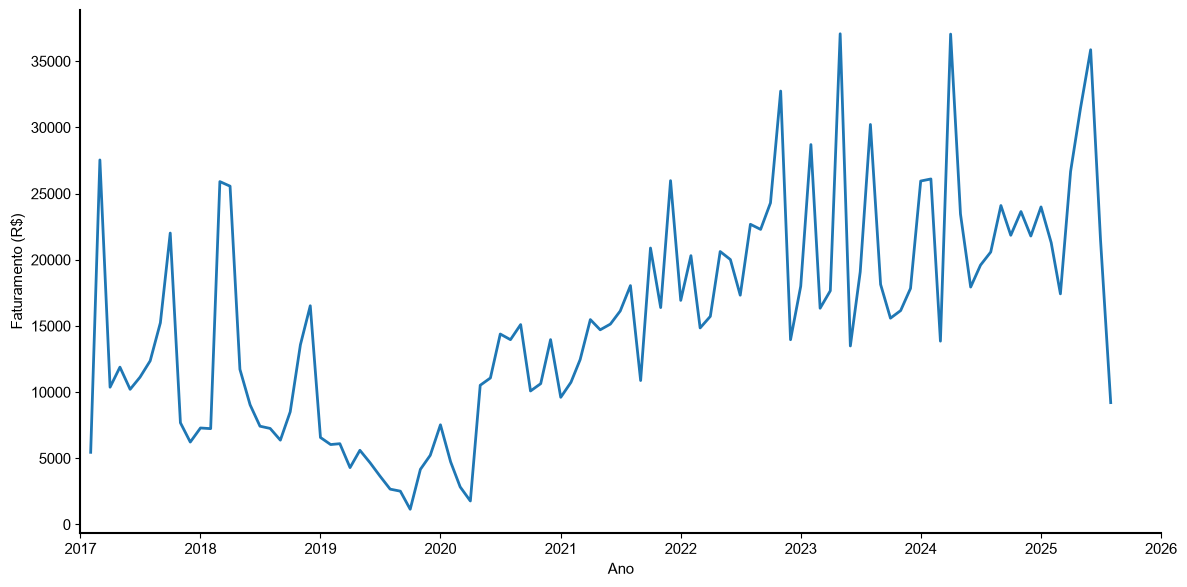

In [7]:
plot_with_style(
    faturamento_mensal,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True
)

## Separação of training and test

Because this is a time series, it is not possible to use the train_test_split of the sklearn, because it could shuffle the series. by this, define-if 80% of the date the training and 20% test.

In [8]:
train_size = int(len(faturamento_mensal) * 0.80)

train = faturamento_mensal.iloc[:train_size].copy()
test = faturamento_mensal.iloc[train_size:].copy()

## `model Naive Forecast (Baseline)`

this model realiza a forecasting copiando-if the month previous, ele is simples for garantir comparações.

In [9]:
pred_naive = test.shift(1)
pred_naive.iloc[0] = train.iloc[-1]

In [10]:
mae_naive = mean_absolute_error(test, pred_naive)

rmse_naive = np.sqrt(
    mean_squared_error(test, pred_naive)
)

print(f"MAE - Naive: {mae_naive:.2f}")
print(f"RMSE - Naive: {rmse_naive:.2f}")

MAE - Naive: 6210.80
RMSE - Naive: 8486.48


In [11]:
grafico_naive = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Naive': pred_naive
})

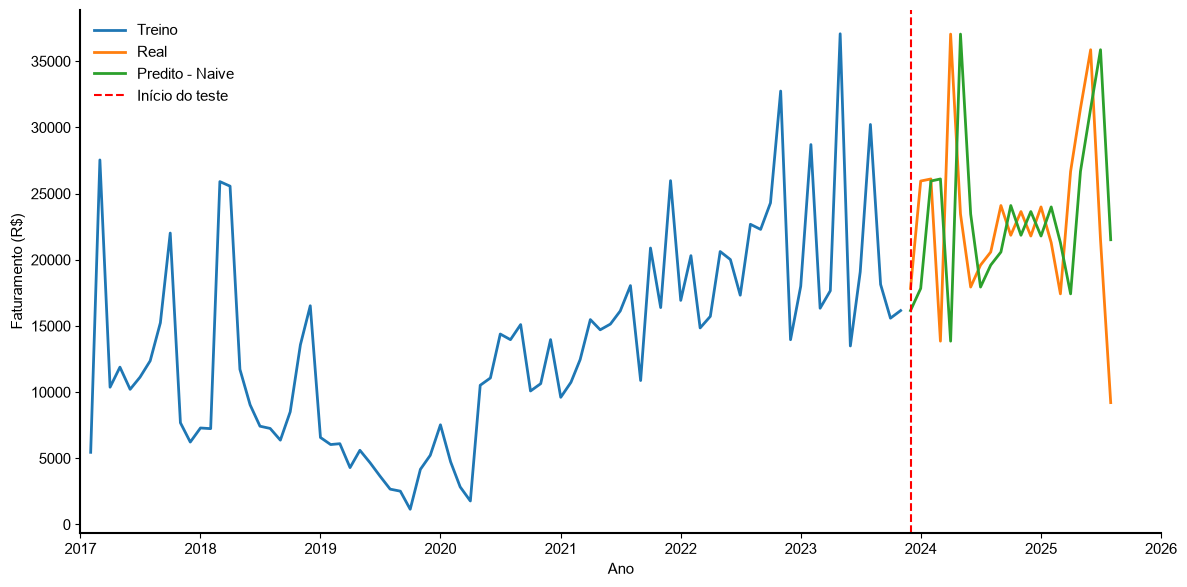

In [12]:
plot_with_style(
    grafico_naive,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

---

## `model Holt-Winters (ExponentialSmoothing)`

### 01 - trend additive and seasonality none

In [13]:
modelo_hw_01 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal=None # seasonality none
)

ajuste_hw_01 = modelo_hw_01.fit()

pred_hw_01 = ajuste_hw_01.forecast(len(test))

In [14]:
mae_hw_01 = mean_absolute_error(
    test,
    pred_hw_01
)

rmse_hw_01 = np.sqrt(
    mean_squared_error(test, pred_hw_01)
)

print(f"MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Nula): {mae_hw_01:.2f}")
print(f"RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Nula): {rmse_hw_01:.2f}")

MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Nula): 4777.43
RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Nula): 6685.91


In [15]:
grafico_hw_01 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend additive and seasonality none)': pred_hw_01
})

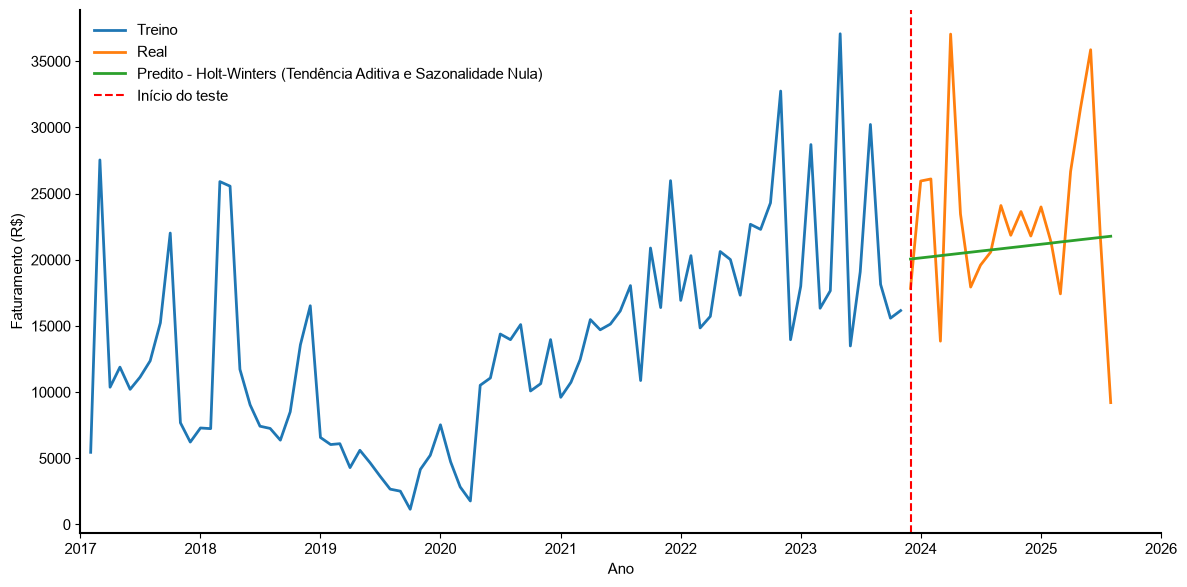

In [16]:
plot_with_style(
    grafico_hw_01,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

### 02 - trend multiplicative and seasonality none

In [17]:
modelo_hw_02 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal=None # seasonality none
)

ajuste_hw_02 = modelo_hw_02.fit()

pred_hw_02 = ajuste_hw_02.forecast(len(test))

In [18]:
mae_hw_02 = mean_absolute_error(
    test,
    pred_hw_02
)

rmse_hw_02 = np.sqrt(
    mean_squared_error(test, pred_hw_02)
)

print(f"MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Nula): {mae_hw_02:.2f}")
print(f"RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Nula): {rmse_hw_02:.2f}")

MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Nula): 4987.02
RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Nula): 6841.91


In [19]:
grafico_hw_02 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend multiplicative and seasonality none)': pred_hw_02
})

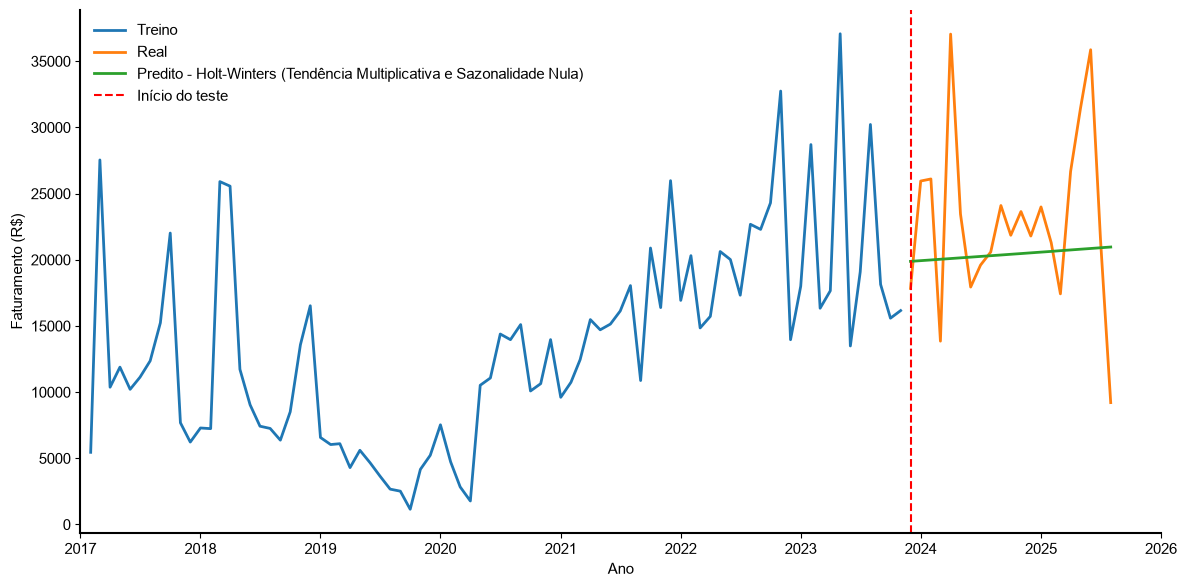

In [20]:
plot_with_style(
    grafico_hw_02,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

### 03 - trend and seasonality Aditivas

#### period seasonal = 3 months

In [30]:
modelo_hw_03 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="add", # seasonality additive
    seasonal_periods=3 # period seasonal of 3 months (1 trimestre)
)

ajuste_hw_03 = modelo_hw_03.fit()

pred_hw_03 = ajuste_hw_03.forecast(len(test))

In [31]:
mae_hw_03 = mean_absolute_error(
    test,
    pred_hw_03
)

rmse_hw_03 = np.sqrt(
    mean_squared_error(test, pred_hw_03)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): {mae_hw_03:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): {rmse_hw_03:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): 6405.67
RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): 8561.78


In [ ]:
grafico_hw_03 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality additive)': pred_hw_03
})

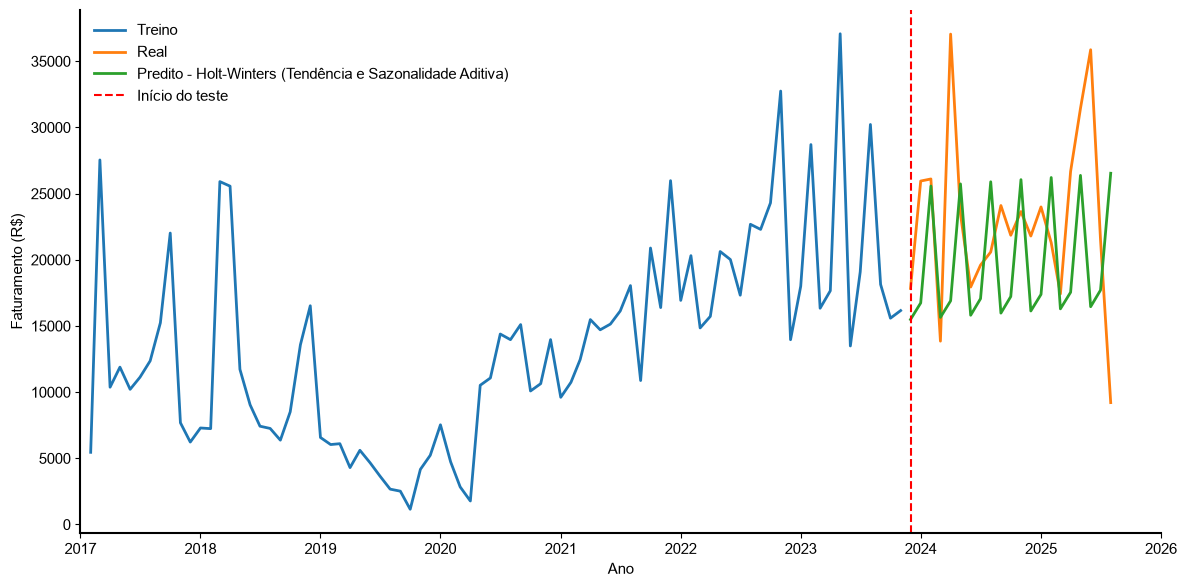

In [ ]:
plot_with_style(
    grafico_hw_03,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal = 5 months

In [ ]:
modelo_hw_03 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="add", # seasonality additive
    seasonal_periods=5 # period seasonal of 5 months
)

ajuste_hw_03 = modelo_hw_03.fit()

pred_hw_03 = ajuste_hw_03.forecast(len(test))

In [ ]:
mae_hw_03 = mean_absolute_error(
    test,
    pred_hw_03
)

rmse_hw_03 = np.sqrt(
    mean_squared_error(test, pred_hw_03)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): {mae_hw_03:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): {rmse_hw_03:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): 4712.41
RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): 6673.37


In [ ]:
grafico_hw_03 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality additive)': pred_hw_03
})

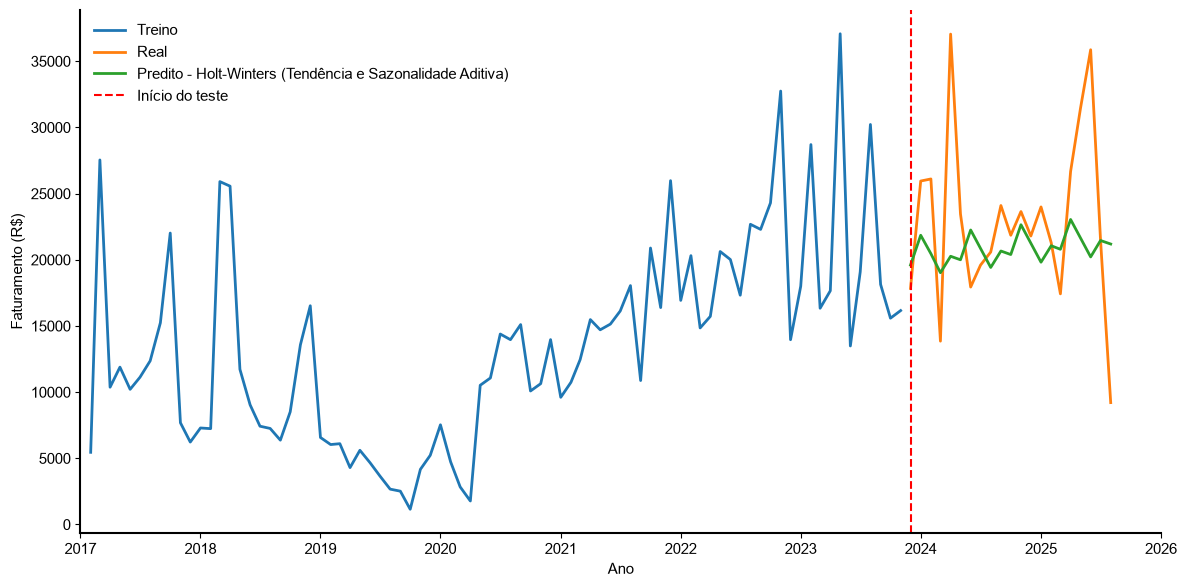

In [ ]:
plot_with_style(
    grafico_hw_03,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal = 6 months

In [ ]:
modelo_hw_03 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="add", # seasonality additive
    seasonal_periods=6 # period seasonal of 6 months (2 trimestres)
)

ajuste_hw_03 = modelo_hw_03.fit()

pred_hw_03 = ajuste_hw_03.forecast(len(test))

In [ ]:
mae_hw_03 = mean_absolute_error(
    test,
    pred_hw_03
)

rmse_hw_03 = np.sqrt(
    mean_squared_error(test, pred_hw_03)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): {mae_hw_03:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): {rmse_hw_03:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): 5796.52
RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): 7929.12


In [ ]:
grafico_hw_03 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality additive)': pred_hw_03
})

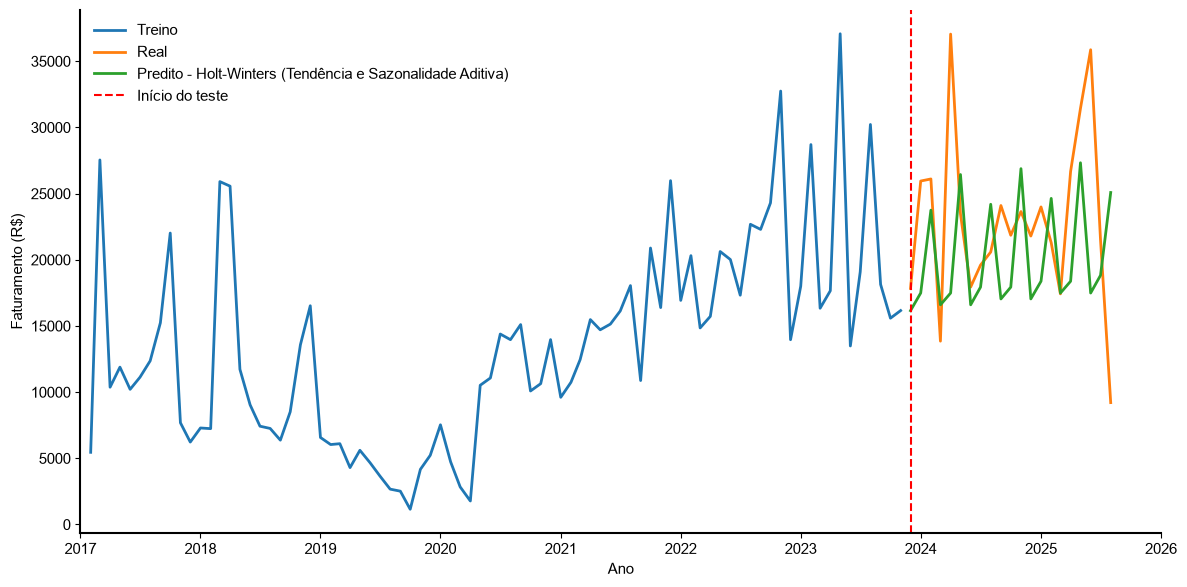

In [ ]:
plot_with_style(
    grafico_hw_03,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal = 12 months

In [ ]:
modelo_hw_03 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="add", # seasonality additive
    seasonal_periods=12 # period seasonal of 12 months (4 trimestres)
)

ajuste_hw_03 = modelo_hw_03.fit()

pred_hw_03 = ajuste_hw_03.forecast(len(test))

In [ ]:
mae_hw_03 = mean_absolute_error(
    test,
    pred_hw_03
)

rmse_hw_03 = np.sqrt(
    mean_squared_error(test, pred_hw_03)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): {mae_hw_03:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): {rmse_hw_03:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Aditiva): 5099.25
RMSE - Holt-Winters (Tendência e Sazonalidade Aditiva): 6805.99


In [ ]:
grafico_hw_03 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality additive)': pred_hw_03
})

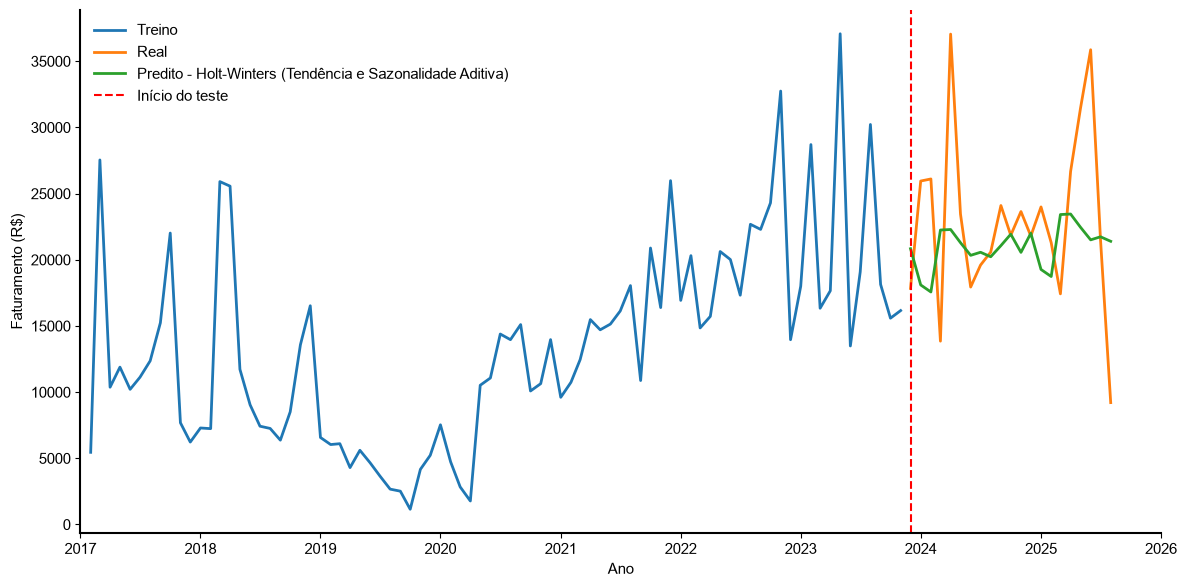

In [ ]:
plot_with_style(
    grafico_hw_03,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

### 04 - trend additive and seasonality multiplicative

#### period seasonal of 3 months

In [ ]:
modelo_hw_04 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=3 # period seasonal of 3 months (1 trimestre)
)

ajuste_hw_04 = modelo_hw_04.fit()

pred_hw_04 = ajuste_hw_04.forecast(len(test))

In [ ]:
mae_hw_04 = mean_absolute_error(
    test,
    pred_hw_04
)

rmse_hw_04 = np.sqrt(
    mean_squared_error(test, pred_hw_04)
)

print(f"MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {mae_hw_04:.2f}")
print(f"RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {rmse_hw_04:.2f}")

MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 5663.16
RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 7930.99


In [ ]:
grafico_hw_04 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend additive and seasonality multiplicative)': pred_hw_04
})

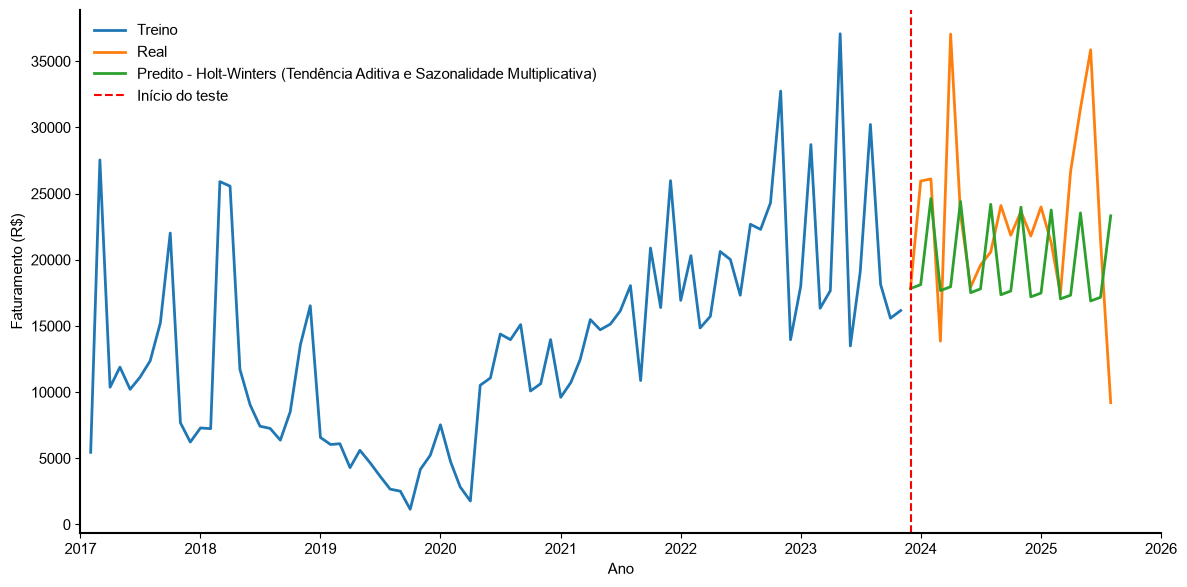

In [ ]:
plot_with_style(
    grafico_hw_04,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 5 months

In [ ]:
modelo_hw_04 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=5 # period seasonal of 5 months
)

ajuste_hw_04 = modelo_hw_04.fit()

pred_hw_04 = ajuste_hw_04.forecast(len(test))

In [ ]:
mae_hw_04 = mean_absolute_error(
    test,
    pred_hw_04
)

rmse_hw_04 = np.sqrt(
    mean_squared_error(test, pred_hw_04)
)

print(f"MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {mae_hw_04:.2f}")
print(f"RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {rmse_hw_04:.2f}")

MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 4665.66
RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 6765.55


In [ ]:
grafico_hw_04 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend additive and seasonality multiplicative)': pred_hw_04
})

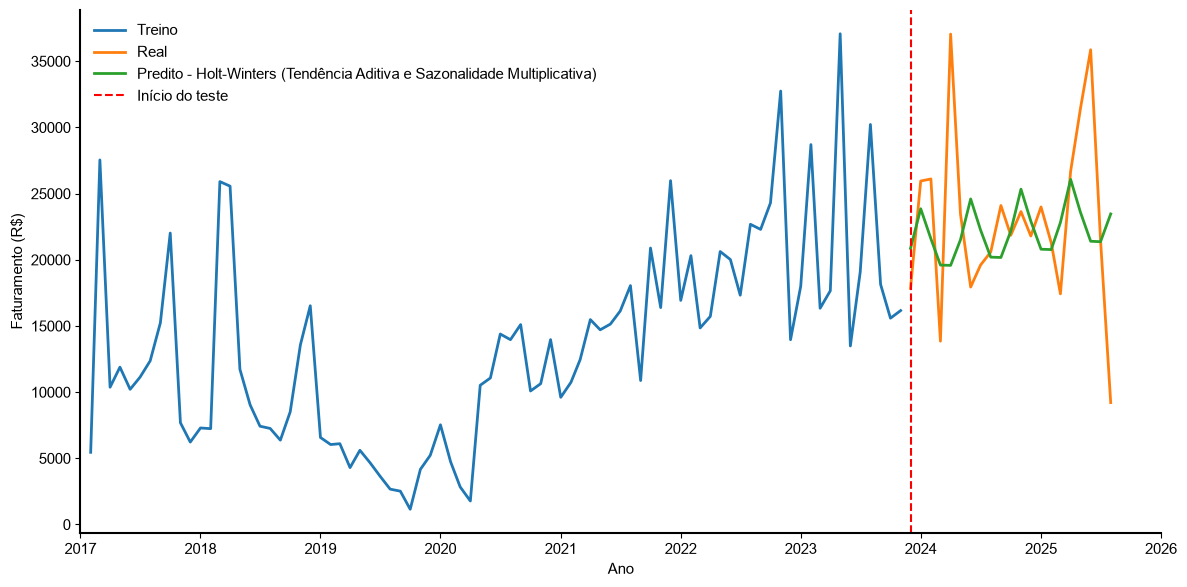

In [ ]:
plot_with_style(
    grafico_hw_04,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 6 months

In [ ]:
modelo_hw_04 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=6 # period seasonal of 6 months (2 trimestres)
)

ajuste_hw_04 = modelo_hw_04.fit()

pred_hw_04 = ajuste_hw_04.forecast(len(test))

In [ ]:
mae_hw_04 = mean_absolute_error(
    test,
    pred_hw_04
)

rmse_hw_04 = np.sqrt(
    mean_squared_error(test, pred_hw_04)
)

print(f"MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {mae_hw_04:.2f}")
print(f"RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {rmse_hw_04:.2f}")

MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 5683.42
RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 7973.25


In [ ]:
grafico_hw_04 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend additive and seasonality multiplicative)': pred_hw_04
})

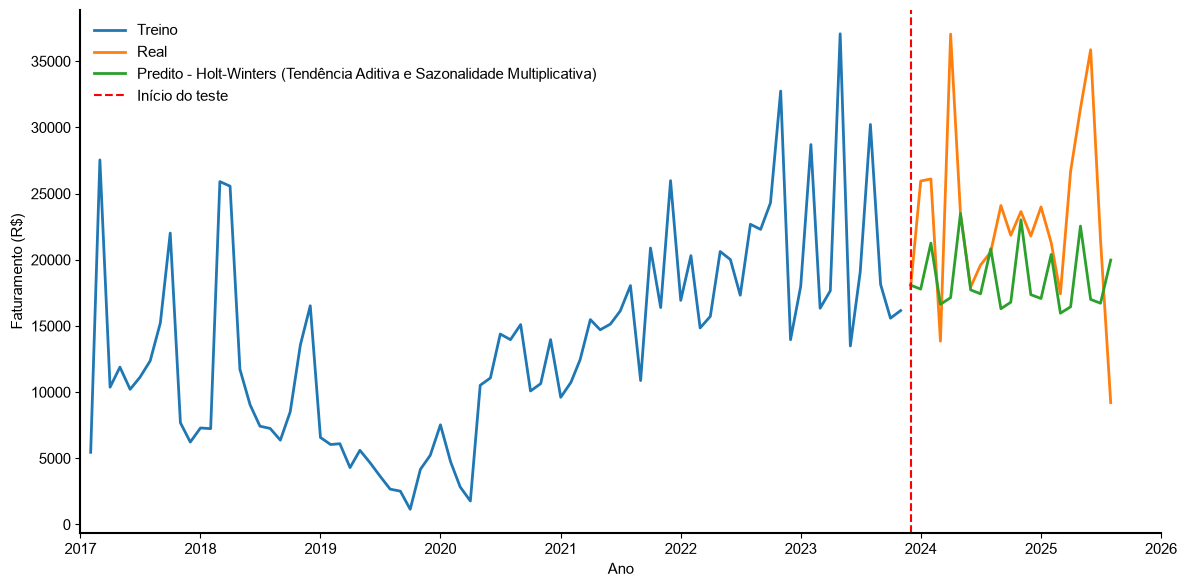

In [ ]:
plot_with_style(
    grafico_hw_04,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 12 months

In [ ]:
modelo_hw_04 = ExponentialSmoothing(
    train,
    trend="add", # trend additive
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=12 # period seasonal of 12 months (1 year)
)

ajuste_hw_04 = modelo_hw_04.fit()

pred_hw_04 = ajuste_hw_04.forecast(len(test))

c:\Users\Marino\Desktop\MBA - USP\.venv\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [ ]:
mae_hw_04 = mean_absolute_error(
    test,
    pred_hw_04
)

rmse_hw_04 = np.sqrt(
    mean_squared_error(test, pred_hw_04)
)

print(f"MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {mae_hw_04:.2f}")
print(f"RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): {rmse_hw_04:.2f}")

MAE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 5740.18
RMSE - Holt-Winters (Tendência Aditiva e Sazonalidade Multiplicativa): 7615.87


In [ ]:
grafico_hw_04 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend additive and seasonality multiplicative)': pred_hw_04
})

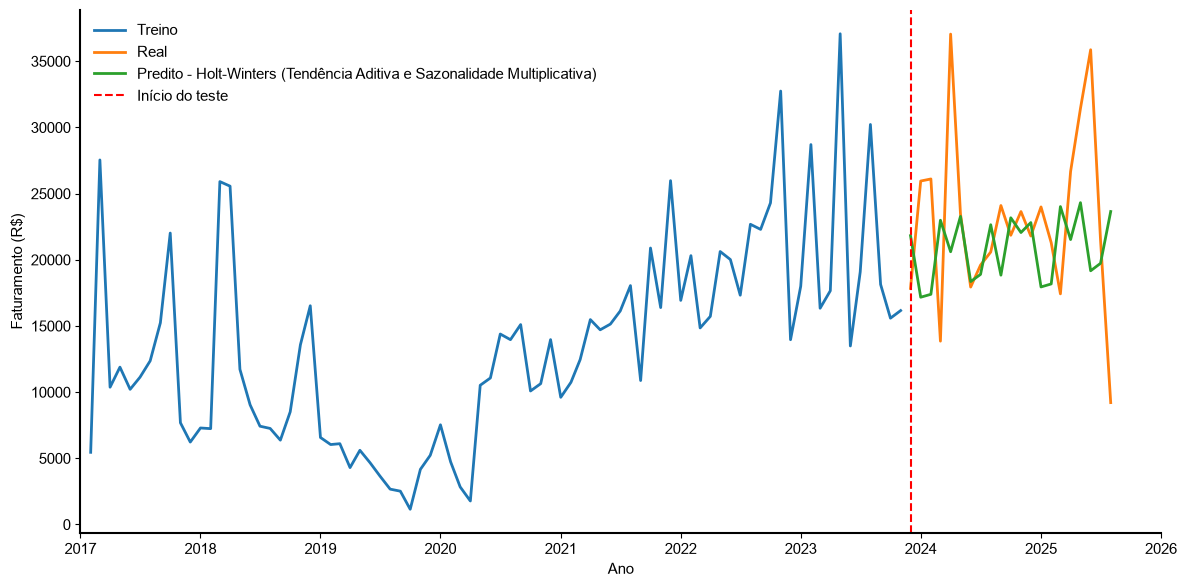

In [ ]:
plot_with_style(
    grafico_hw_04,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

### 05 - trend multiplicative and seasonality additive

#### period seasonal of 3 months

In [ ]:
modelo_hw_05 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="add", # seasonality additive
    seasonal_periods=3 # period seasonal of 3 months (1 trimestre)
)

ajuste_hw_05 = modelo_hw_05.fit()

pred_hw_05 = ajuste_hw_05.forecast(len(test))

In [ ]:
mae_hw_05 = mean_absolute_error(
    test,
    pred_hw_05
)

rmse_hw_05 = np.sqrt(
    mean_squared_error(test, pred_hw_05)
)

print(f"MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {mae_hw_05:.2f}")
print(f"RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {rmse_hw_05:.2f}")

MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 6762.25
RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 8884.62


In [ ]:
grafico_hw_05 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend multiplicative and seasonality additive)': pred_hw_05
})

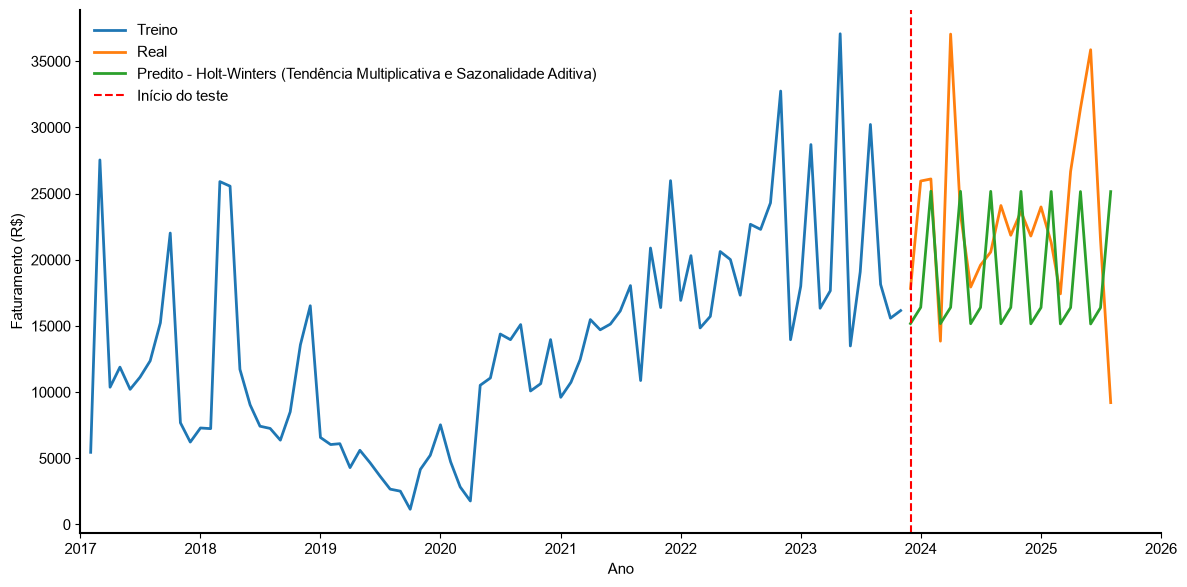

In [ ]:
plot_with_style(
    grafico_hw_05,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 5 months

In [ ]:
modelo_hw_05 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="add", # seasonality additive
    seasonal_periods=5 # period seasonal of 6 months
)

ajuste_hw_05 = modelo_hw_05.fit()

pred_hw_05 = ajuste_hw_05.forecast(len(test))

In [ ]:
mae_hw_05 = mean_absolute_error(
    test,
    pred_hw_05
)

rmse_hw_05 = np.sqrt(
    mean_squared_error(test, pred_hw_05)
)

print(f"MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {mae_hw_05:.2f}")
print(f"RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {rmse_hw_05:.2f}")

MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 4831.01
RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 6657.84


In [ ]:
grafico_hw_05 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend multiplicative and seasonality additive)': pred_hw_05
})

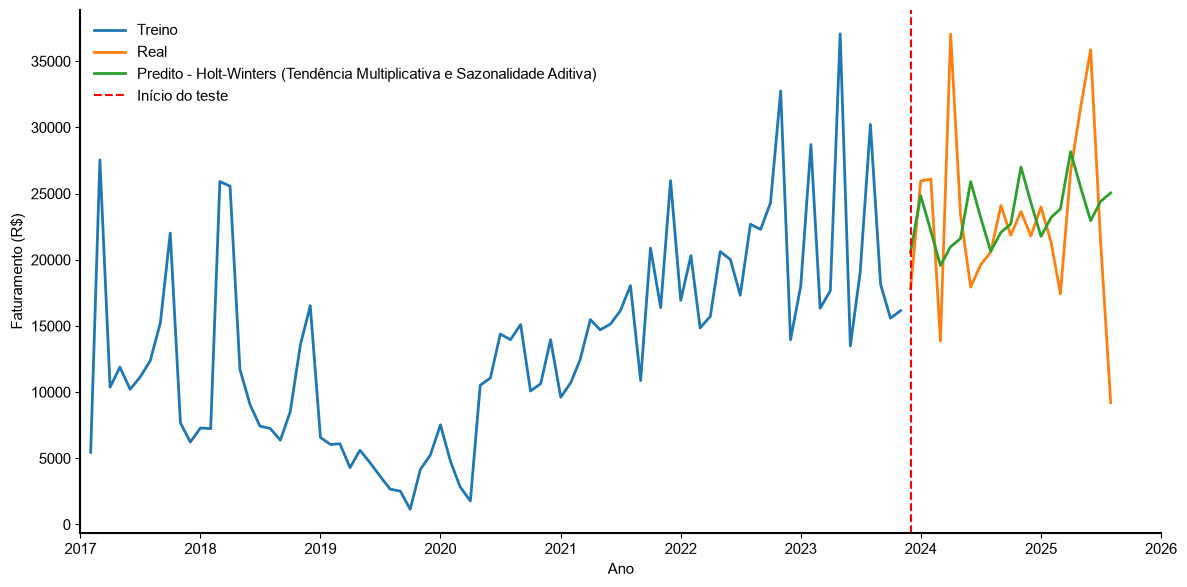

In [ ]:
plot_with_style(
    grafico_hw_05,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 6 months

In [ ]:
modelo_hw_05 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="add", # seasonality additive
    seasonal_periods=6 # period seasonal of 6 months
)

ajuste_hw_05 = modelo_hw_05.fit()

pred_hw_05 = ajuste_hw_05.forecast(len(test))

In [ ]:
mae_hw_05 = mean_absolute_error(
    test,
    pred_hw_05
)

rmse_hw_05 = np.sqrt(
    mean_squared_error(test, pred_hw_05)
)

print(f"MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {mae_hw_05:.2f}")
print(f"RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {rmse_hw_05:.2f}")

MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 6062.32
RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 8152.76


In [ ]:
grafico_hw_05 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend multiplicative and seasonality additive)': pred_hw_05
})

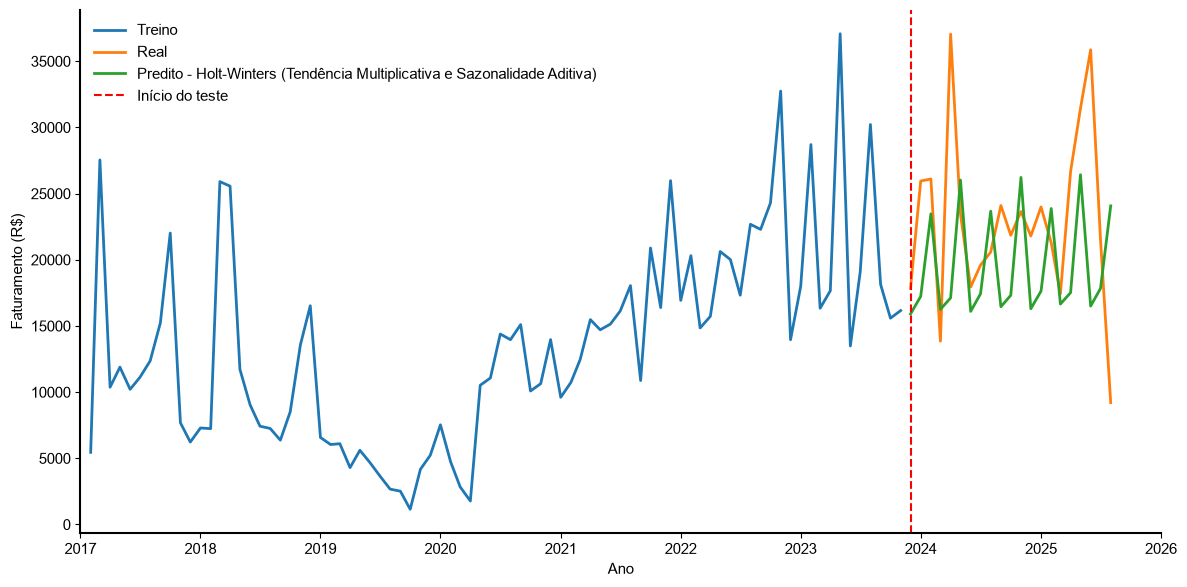

In [ ]:
plot_with_style(
    grafico_hw_05,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 12 months

In [ ]:
modelo_hw_05 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="add", # seasonality additive
    seasonal_periods=12 # period seasonal of 12 months (1 year)
)

ajuste_hw_05 = modelo_hw_05.fit()

pred_hw_05 = ajuste_hw_05.forecast(len(test))

In [ ]:
mae_hw_05 = mean_absolute_error(
    test,
    pred_hw_05
)

rmse_hw_05 = np.sqrt(
    mean_squared_error(test, pred_hw_05)
)

print(f"MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {mae_hw_05:.2f}")
print(f"RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): {rmse_hw_05:.2f}")

MAE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 5120.76
RMSE - Holt-Winters (Tendência Multiplicativa e Sazonalidade Aditiva): 7252.45


In [ ]:
grafico_hw_05 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend multiplicative and seasonality additive)': pred_hw_05
})

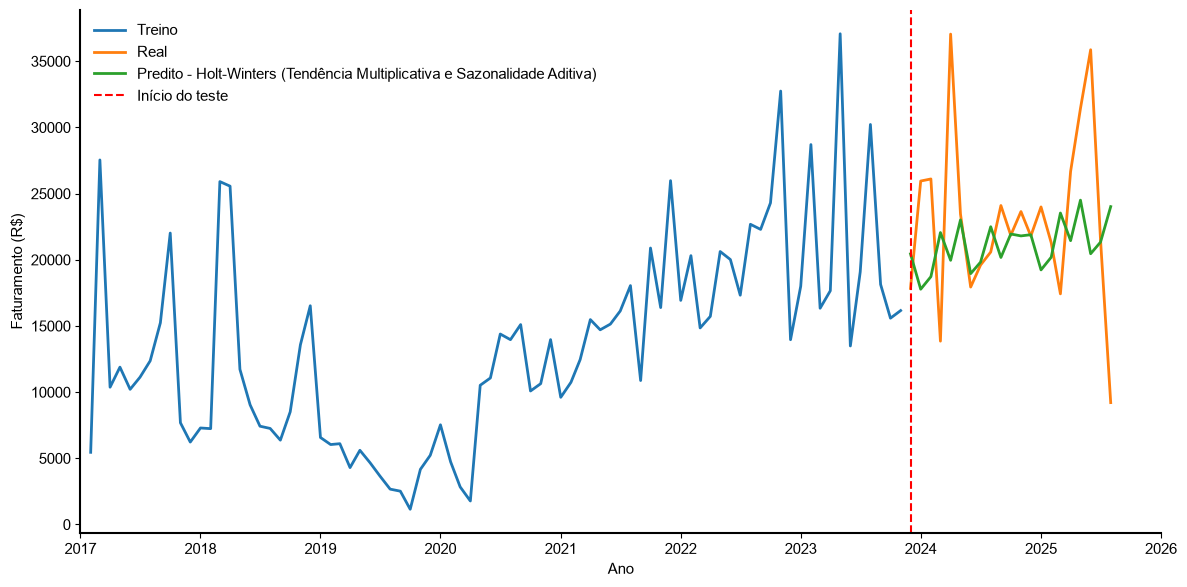

In [ ]:
plot_with_style(
    grafico_hw_05,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

### 06 - trend and seasonality multiplicative

#### period seasonal of 3 months

In [ ]:
modelo_hw_06 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=3 # period seasonal of 3 months (1 trimestre)
)

ajuste_hw_06 = modelo_hw_06.fit()

pred_hw_06 = ajuste_hw_06.forecast(len(test))

In [ ]:
mae_hw_06 = mean_absolute_error(
    test,
    pred_hw_06
)

rmse_hw_06 = np.sqrt(
    mean_squared_error(test, pred_hw_06)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {mae_hw_06:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {rmse_hw_06:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 5600.20
RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 7914.21


In [ ]:
grafico_hw_06 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality multiplicative)': pred_hw_06
})

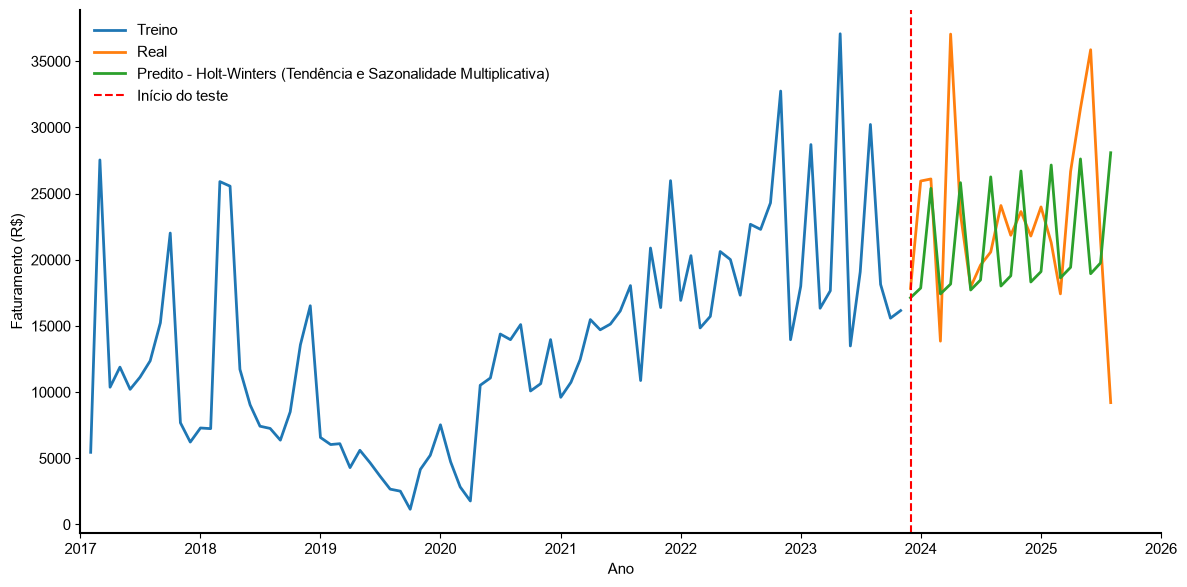

In [ ]:
plot_with_style(
    grafico_hw_06,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 5 months

In [ ]:
modelo_hw_06 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=5 # period seasonal of 5 months
)

ajuste_hw_06 = modelo_hw_06.fit()

pred_hw_06 = ajuste_hw_06.forecast(len(test))

In [ ]:
mae_hw_06 = mean_absolute_error(
    test,
    pred_hw_06
)

rmse_hw_06 = np.sqrt(
    mean_squared_error(test, pred_hw_06)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {mae_hw_06:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {rmse_hw_06:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 4670.60
RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 6742.91


In [ ]:
grafico_hw_06 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality multiplicative)': pred_hw_06
})

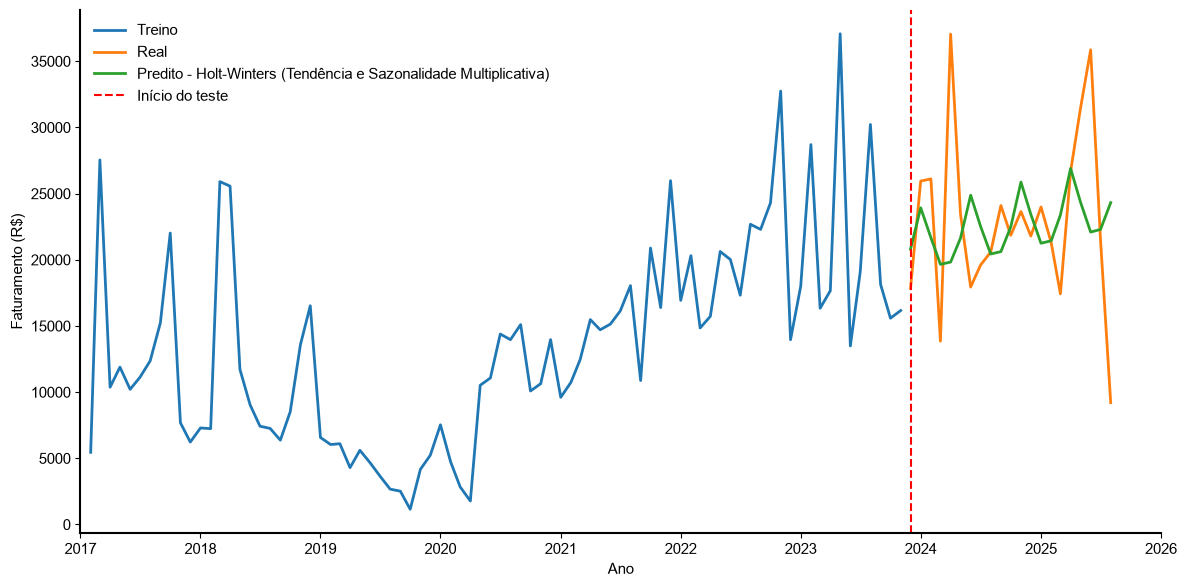

In [ ]:
plot_with_style(
    grafico_hw_06,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 6 months

In [ ]:
modelo_hw_06 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=6 # period seasonal of 6 months (2 trimestres)
)

ajuste_hw_06 = modelo_hw_06.fit()

pred_hw_06 = ajuste_hw_06.forecast(len(test))

In [ ]:
mae_hw_06 = mean_absolute_error(
    test,
    pred_hw_06
)

rmse_hw_06 = np.sqrt(
    mean_squared_error(test, pred_hw_06)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {mae_hw_06:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {rmse_hw_06:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 5100.73
RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 7182.87


In [ ]:
grafico_hw_06 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality multiplicative)': pred_hw_06
})

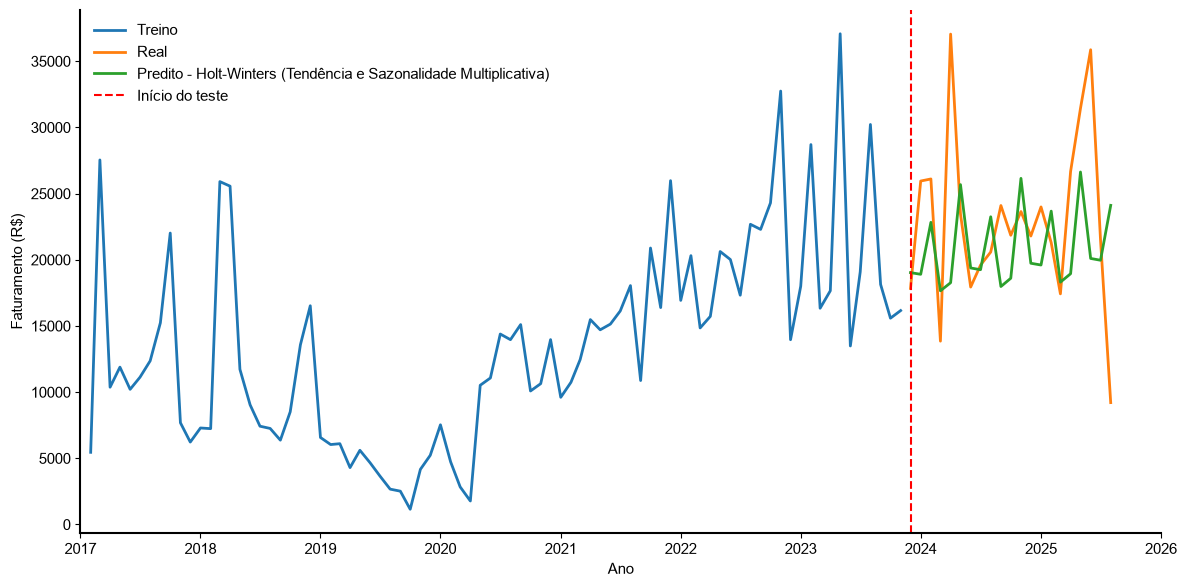

In [ ]:
plot_with_style(
    grafico_hw_06,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

#### period seasonal of 12 months

In [ ]:
modelo_hw_06 = ExponentialSmoothing(
    train,
    trend="mul", # trend multiplicative
    seasonal="mul", # seasonality multiplicative
    seasonal_periods=12 # period seasonal of 12 months (1 year)
)

ajuste_hw_06 = modelo_hw_06.fit()

pred_hw_06 = ajuste_hw_06.forecast(len(test))

In [ ]:
mae_hw_06 = mean_absolute_error(
    test,
    pred_hw_06
)

rmse_hw_06 = np.sqrt(
    mean_squared_error(test, pred_hw_06)
)

print(f"MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {mae_hw_06:.2f}")
print(f"RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): {rmse_hw_06:.2f}")

MAE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 5418.00
RMSE - Holt-Winters (Tendência e Sazonalidade Multiplicativa): 7701.16


In [ ]:
grafico_hw_06 = pd.DataFrame({
    'Treino': train,
    'Real': test,
    'Predito - Holt-Winters (trend and seasonality multiplicative)': pred_hw_06
})

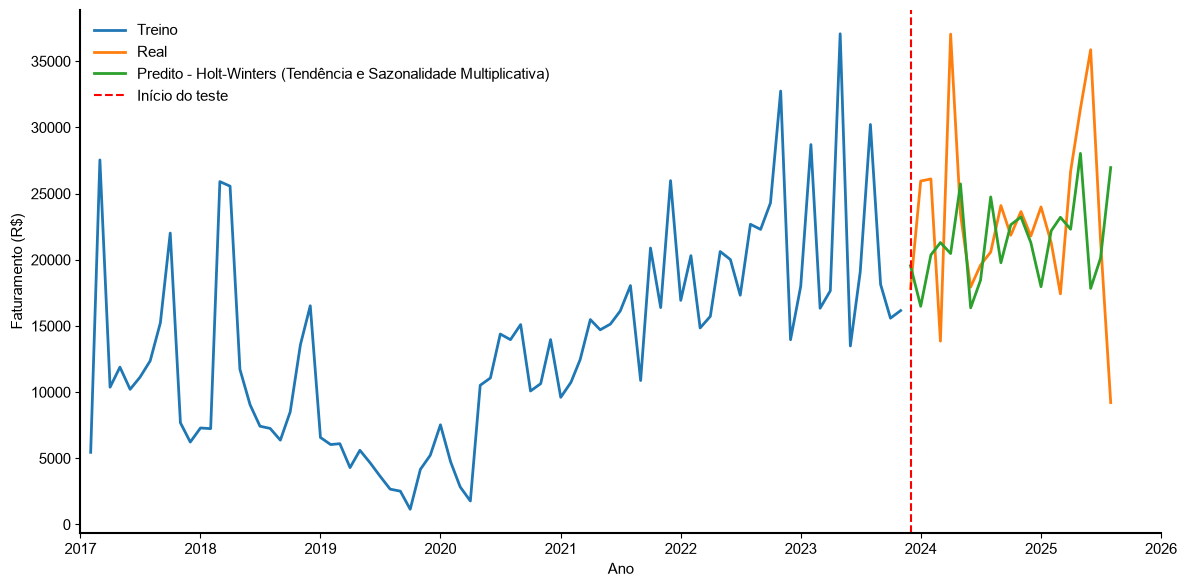

In [ ]:
plot_with_style(
    grafico_hw_06,
    x_label='Ano',
    y_label='revenue (R$)',
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=('2017-01-01', '2026-01-01'),
    year_ticks=True,
    vline=test.index[0],
    vline_label='start of the test'
)

---

## `ARIMA (p,d,q) Manual`

Partindo of the série temporal `revenue_monthly`, queremos determinar `ARIMA(p,d,q)`, where:
* d: quantas diferenciações are necessary for tornar a série stationary;
* p: ordem of the componente autorregressivo;
* q: ordem of the componente of mean móvel.

for this, seguiremos a seguinte ordem of stages:
1) test of stationarity:
    * if for stationary: `d=0`
    * if not for stationary -> perform a diferenciação -> novo test ADFuller -> determinar `d` for that whether stationary

2) perform a analysis of the functions of correlation and correlation parcial (ACF and PACF), where a ACF determina `p` and PACF determina `q`

### test of stationarity (Augmented Dickey-Fuller (ADF))

1) the interpretar the test ADF
    * hypothesis none (H0): a série possui raiz unitária -> not is stationary
    * hypothesis not-none (H1): a série not possui raiz unitária -> stationary

    * analyzing the p-value: p < 0.05 -> rejeita-if H0 -> série stationary

In [ ]:
from statsmodels.tsa.stattools import adfuller

resultado_adf = adfuller(train)

print(f"Estatística ADF: {resultado_adf[0]:.4f}")
print(f"p-valor: {resultado_adf[1]:.4f}")

if resultado_adf[1] < 0.05:
    print("a série temporal is stationary (rejeita H0).")
else:
    print("a série temporal not is stationary (falha in rejeitar H0).")

Estatística ADF: -0.9874
p-valor: 0.7578
A série temporal não é estacionária (falha em rejeitar H0).


Realiza-if a first diferenciação: $\Delta y_t = y_t - y_{t-1}$

In [ ]:
train_diff1 = train.diff().dropna()

In [ ]:
resultado_adf_diff1 = adfuller(train_diff1)

print(
    f"Estatística ADF: "
    f"{resultado_adf_diff1[0]:.4f}"
)

print(
    f"p-valor: "
    f"{resultado_adf_diff1[1]:.4f}"
)
if resultado_adf_diff1[1] < 0.05:
    print("a série temporal is stationary (rejeita H0).")
else:
    print("a série temporal not is stationary (falha in rejeitar H0).")

Estatística ADF: -7.8093
p-valor: 0.0000
A série temporal é estacionária (rejeita H0).


`Conclusão:` the após perform a diferenciação a série if torna stationary, define-if, therefore, d=1

### function of Autocorrelação and function of Autocorrelação Parcial

* `p`: odem autorregressiva: procure in the PACF the last lag sinificativo before of a série "cortar".
* `q`: ordem of mean móvel: procure in the ACF the last lag significant before of a série "cortar".
* significant significa sair of the intervalo of confiança.

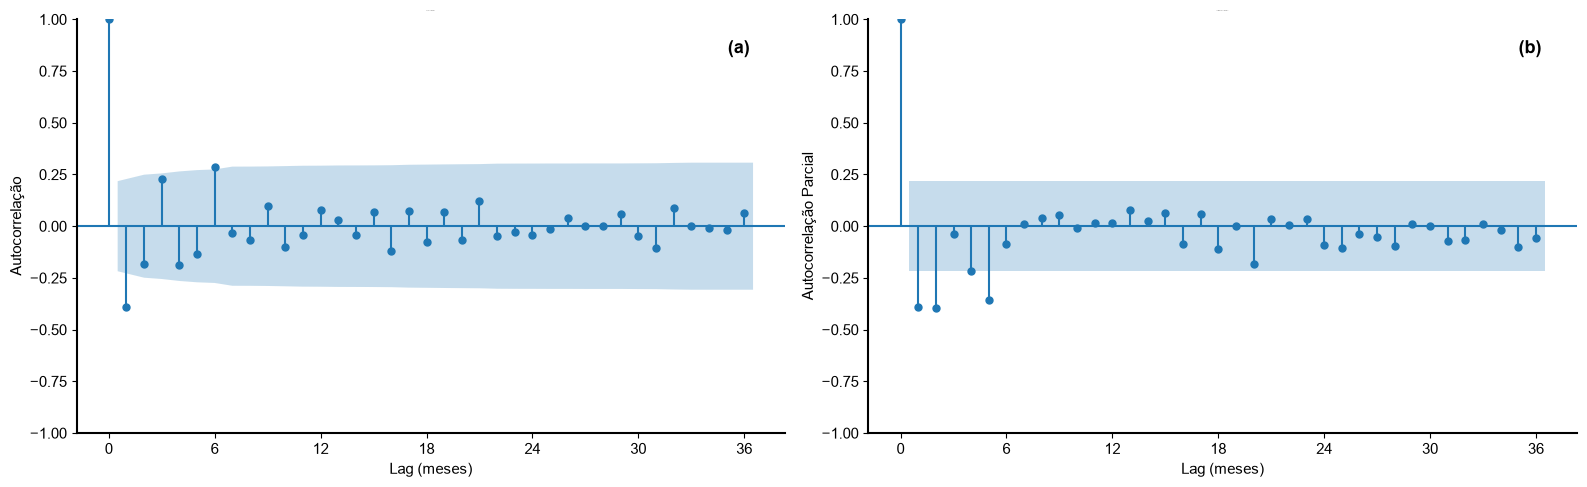

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

max_lag = 36

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF
plot_acf(
    train_diff1,
    lags=max_lag,
    ax=axes[0]
)
axes[0].set_xlabel(
    'Lag (months)',
    fontsize=11,
    fontname='Arial'
)
axes[0].set_ylabel(
    'Autocorrelação',
    fontsize=11,
    fontname='Arial'
)
axes[0].grid(False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].spines['left'].set_linewidth(1.5)
axes[0].spines['bottom'].set_linewidth(1.5)
axes[0].spines['left'].set_color('black')
axes[0].spines['bottom'].set_color('black')
axes[0].set_xticks(list(range(0, max_lag + 1, 6)))
#axes[0].set_title(
#    'ACF of the Série Diferenciada',
#    fontsize=14,
#    fontweight='bold',
#    fontname='Arial'
#)
axes[0].text(
    0.95, 0.95, '(a)',
    transform=axes[0].transAxes,
    ha='right',
    va='top',
    fontsize=13,
    fontweight='bold',
    fontname='Arial'
)

# PACF
plot_pacf(
    train_diff1,
    lags=max_lag,
    ax=axes[1]
)
axes[1].set_xlabel(
    'Lag (months)',
    fontsize=11,
    fontname='Arial'
)
axes[1].set_ylabel(
    'Autocorrelação Parcial',
    fontsize=11,
    fontname='Arial'
)
axes[1].grid(False)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_linewidth(1.5)
axes[1].spines['bottom'].set_linewidth(1.5)
axes[1].spines['left'].set_color('black')
axes[1].spines['bottom'].set_color('black')
axes[1].set_xticks(list(range(0, max_lag + 1, 6)))
#axes[1].set_title(
#    'PACF of the Série Diferenciada',
#    fontsize=14,
#    fontweight='bold',
#    fontname='Arial'
#)
axes[1].text(
    0.95, 0.95, '(b)',
    transform=axes[1].transAxes,
    ha='right',
    va='top',
    fontsize=13,
    fontweight='bold',
    fontname='Arial'
)

plt.tight_layout()
plt.show()

`Conclusão:` The analysis of the ACF garante that there are a corte significant in the first lag, indicando that the componente of the mean móvel is of ordem 1 (q=1). also was analyzed a PACF, with dois cortes significant in the first and in the segundo lag, indicando that a ordem of the componente autorregressiva is 2 (p=2). 

a partir destas analyses, is possible build and testar the model ARIMA(2,1,1) and comparar with the model otimizado pelo Auto SARIMA.

### ARIMA(2,1,1)

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

modelo = ARIMA(
    train,
    order=(2,1,1)
)

ajuste_arima_211 = modelo.fit()

pred_arima_211 = ajuste_arima_211.forecast(
    steps=len(test)
)

In [ ]:
mae_arima_211 = mean_absolute_error(test, pred_arima_211)

rmse_arima_211 = np.sqrt(mean_squared_error(test, pred_arima_211))

print(f'AIC: {ajuste_arima_211.aic:.2f}')
print(f'MAE: {mae_arima_211:.2f}')
print(f'RMSE: {rmse_arima_211:.2f}')

AIC: 1645.78
MAE: 5392.37
RMSE: 7162.75


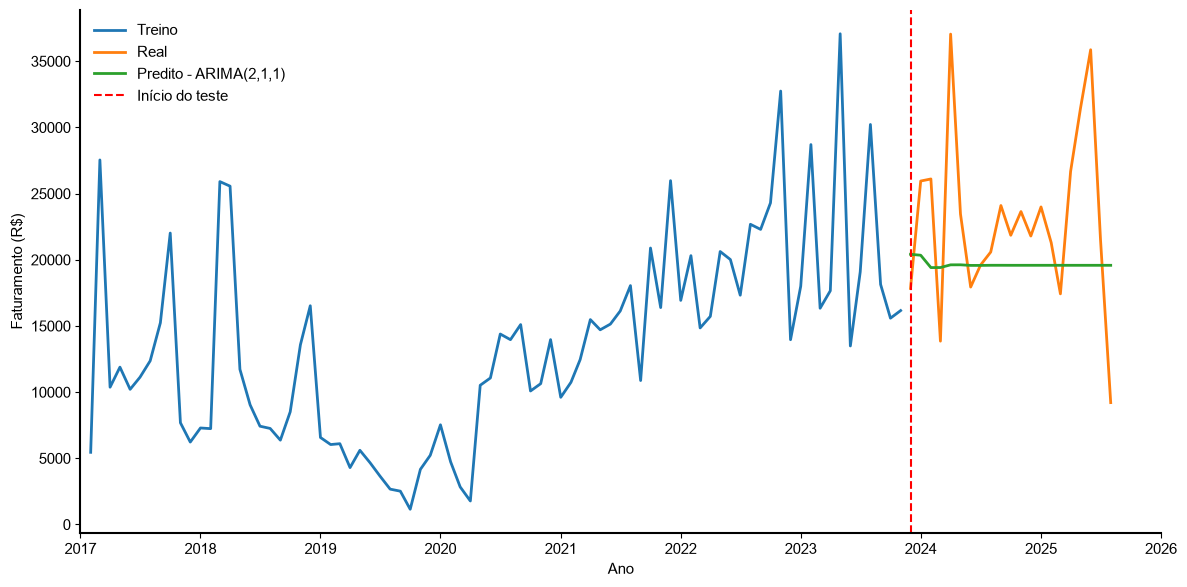

In [ ]:
grafico_arima = pd.DataFrame({
    "Treino": train,
    "Real": test,
    "Predito - ARIMA(2,1,1)": pred_arima_211
})

plot_with_style(
    grafico_arima,
    x_label="Ano",
    y_label="revenue (R$)",
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=("2017-01-01", "2026-01-01"),
    year_ticks=True,
    vline=test.index[0],
    vline_label="start of the test"
)

### Auto-ARIMA

#### period seasonal of 1 mes

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=1,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[1] intercept   : AIC=1675.506, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[1] intercept   : AIC=1646.094, Time=0.04 sec
 ARIMA(0,1,2)(0,0,0)[1] intercept   : AIC=1647.417, Time=0.18 sec
 ARIMA(0,1,3)(0,0,0)[1] intercept   : AIC=1646.673, Time=0.04 sec
 ARIMA(0,1,4)(0,0,0)[1] intercept   : AIC=1646.770, Time=0.13 sec
 ARIMA(0,1,5)(0,0,0)[1] intercept   : AIC=1647.386, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[1] intercept   : AIC=1667.087, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[1] intercept   : AIC=1647.605, Time=0.03 sec
 ARIMA(1,1,2)(0,0,0)[1] intercept   : AIC=inf, Time=0.09 sec
 ARIMA(1,1,3)(0,0,0)[1] intercept   : AIC=1648.397, Time=0.04 sec
 ARIMA(1,1,4)(0,0,0)[1] intercept   : AIC=1653.105, Time=0.08 sec
 ARIMA(2,1,0)(0,0,0)[1] intercept   : AIC=1652.282, Time=0.02 sec
 ARIMA(2,1,1)(0,0,0)[1] intercept   : AIC=1647.439, Time=0.05 sec
 ARIMA(2,1,2)(0,0,0)[1] intercept   : AIC=1647.557, Time=0.04 sec
 ARIMA(2,1,3)(0,0,0)[1] intercept   : AIC=1647.414, Time=0.08 sec
 ARIMA(3,1,0)(0

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 5783.39
RMSE - Auto-SARIMA: 7597.48


#### period seasonal of 2 mes

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=2,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[2] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[2] intercept   : AIC=1672.070, Time=0.03 sec
 ARIMA(0,1,0)(0,0,2)[2] intercept   : AIC=1673.389, Time=0.04 sec
 ARIMA(0,1,0)(1,0,0)[2] intercept   : AIC=1673.800, Time=0.02 sec
 ARIMA(0,1,0)(1,0,1)[2] intercept   : AIC=1673.966, Time=0.06 sec
 ARIMA(0,1,0)(1,0,2)[2] intercept   : AIC=1672.425, Time=0.09 sec
 ARIMA(0,1,0)(2,0,0)[2] intercept   : AIC=1670.004, Time=0.03 sec
 ARIMA(0,1,0)(2,0,1)[2] intercept   : AIC=1668.997, Time=0.04 sec
 ARIMA(0,1,0)(2,0,2)[2] intercept   : AIC=1669.421, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[2] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[2] intercept   : AIC=1643.440, Time=0.04 sec
 ARIMA(0,1,1)(0,0,2)[2] intercept   : AIC=1645.092, Time=0.05 sec
 ARIMA(0,1,1)(1,0,0)[2] intercept   : AIC=1645.231, Time=0.02 sec
 ARIMA(0,1,1)(1,0,1)[2] intercept   : AIC=1645.268, Time=0.10 sec
 ARIMA(0,1,1)(1,0,2)[2] intercept   : AIC=1644.689, Time=0.05 sec
 ARIMA(0,1

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 6297.30
RMSE - Auto-SARIMA: 8104.89


#### period seasonal of 3 months

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=3,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[3] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[3] intercept   : AIC=1674.288, Time=0.02 sec
 ARIMA(0,1,0)(0,0,2)[3] intercept   : AIC=1669.133, Time=0.03 sec
 ARIMA(0,1,0)(1,0,0)[3] intercept   : AIC=1672.251, Time=0.02 sec
 ARIMA(0,1,0)(1,0,1)[3] intercept   : AIC=1670.192, Time=0.05 sec
 ARIMA(0,1,0)(1,0,2)[3] intercept   : AIC=1670.084, Time=0.06 sec
 ARIMA(0,1,0)(2,0,0)[3] intercept   : AIC=1667.536, Time=0.03 sec
 ARIMA(0,1,0)(2,0,1)[3] intercept   : AIC=1669.534, Time=0.04 sec
 ARIMA(0,1,0)(2,0,2)[3] intercept   : AIC=1671.532, Time=0.09 sec
 ARIMA(0,1,1)(0,0,0)[3] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[3] intercept   : AIC=1647.695, Time=0.04 sec
 ARIMA(0,1,1)(0,0,2)[3] intercept   : AIC=1643.084, Time=0.05 sec
 ARIMA(0,1,1)(1,0,0)[3] intercept   : AIC=1647.409, Time=0.03 sec
 ARIMA(0,1,1)(1,0,1)[3] intercept   : AIC=1646.395, Time=0.11 sec
 ARIMA(0,1,1)(1,0,2)[3] intercept   : AIC=1643.647, Time=0.15 sec
 ARIMA(0,1

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 4955.91
RMSE - Auto-SARIMA: 7037.76


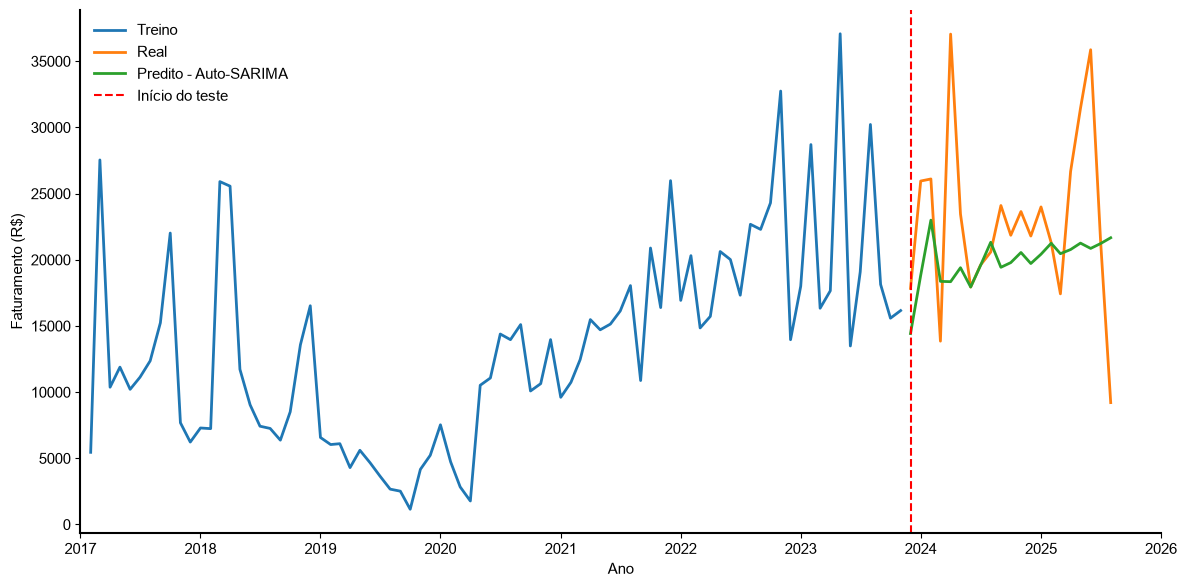

In [ ]:
grafico_auto_sarima = pd.DataFrame({
    "Treino": train,
    "Real": test,
    "Predito - Auto-SARIMA": pred_auto_sarima
})

plot_with_style(
    grafico_auto_sarima,
    x_label="Ano",
    y_label="revenue (R$)",
    figsize=(12, 6),
    marker=None,
    linewidth=2,
    xlim=("2017-01-01", "2026-01-01"),
    year_ticks=True,
    vline=test.index[0],
    vline_label="start of the test"
)

#### period seasonal of 4 months

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=4,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[4] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[4] intercept   : AIC=1673.021, Time=0.04 sec
 ARIMA(0,1,0)(0,0,2)[4] intercept   : AIC=1674.454, Time=0.08 sec
 ARIMA(0,1,0)(1,0,0)[4] intercept   : AIC=1673.779, Time=0.03 sec
 ARIMA(0,1,0)(1,0,1)[4] intercept   : AIC=1673.844, Time=0.10 sec
 ARIMA(0,1,0)(1,0,2)[4] intercept   : AIC=1674.996, Time=0.27 sec
 ARIMA(0,1,0)(2,0,0)[4] intercept   : AIC=1674.433, Time=0.03 sec
 ARIMA(0,1,0)(2,0,1)[4] intercept   : AIC=1674.972, Time=0.08 sec
 ARIMA(0,1,0)(2,0,2)[4] intercept   : AIC=1677.522, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[4] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[4] intercept   : AIC=1645.045, Time=0.05 sec
 ARIMA(0,1,1)(0,0,2)[4] intercept   : AIC=1646.927, Time=0.05 sec
 ARIMA(0,1,1)(1,0,0)[4] intercept   : AIC=1645.109, Time=0.03 sec
 ARIMA(0,1,1)(1,0,1)[4] intercept   : AIC=1647.000, Time=0.05 sec
 ARIMA(0,1,1)(1,0,2)[4] intercept   : AIC=1648.906, Time=0.09 sec
 ARIMA(0,1

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 5193.14
RMSE - Auto-SARIMA: 7123.59


#### period seasonal of 5 months

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=5,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[5] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[5] intercept   : AIC=1674.921, Time=0.03 sec
 ARIMA(0,1,0)(0,0,2)[5] intercept   : AIC=1674.708, Time=0.05 sec
 ARIMA(0,1,0)(1,0,0)[5] intercept   : AIC=1675.659, Time=0.02 sec
 ARIMA(0,1,0)(1,0,1)[5] intercept   : AIC=1675.322, Time=0.06 sec
 ARIMA(0,1,0)(1,0,2)[5] intercept   : AIC=1675.607, Time=0.09 sec
 ARIMA(0,1,0)(2,0,0)[5] intercept   : AIC=1675.276, Time=0.04 sec
 ARIMA(0,1,0)(2,0,1)[5] intercept   : AIC=1676.506, Time=0.11 sec
 ARIMA(0,1,0)(2,0,2)[5] intercept   : AIC=1677.292, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[5] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[5] intercept   : AIC=1647.591, Time=0.03 sec
 ARIMA(0,1,1)(0,0,2)[5] intercept   : AIC=1648.954, Time=0.05 sec
 ARIMA(0,1,1)(1,0,0)[5] intercept   : AIC=1647.684, Time=0.03 sec
 ARIMA(0,1,1)(1,0,1)[5] intercept   : AIC=1647.861, Time=0.16 sec
 ARIMA(0,1,1)(1,0,2)[5] intercept   : AIC=1649.739, Time=0.26 sec
 ARIMA(0,1

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 4568.88
RMSE - Auto-SARIMA: 6579.83


#### period seasonal of 6 months

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=6,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[6] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[6] intercept   : AIC=1669.649, Time=0.03 sec
 ARIMA(0,1,0)(0,0,2)[6] intercept   : AIC=1669.330, Time=0.06 sec
 ARIMA(0,1,0)(1,0,0)[6] intercept   : AIC=1667.999, Time=0.05 sec
 ARIMA(0,1,0)(1,0,1)[6] intercept   : AIC=1669.987, Time=0.08 sec
 ARIMA(0,1,0)(1,0,2)[6] intercept   : AIC=1671.305, Time=0.13 sec
 ARIMA(0,1,0)(2,0,0)[6] intercept   : AIC=1669.973, Time=0.04 sec
 ARIMA(0,1,0)(2,0,1)[6] intercept   : AIC=1671.370, Time=0.14 sec
 ARIMA(0,1,0)(2,0,2)[6] intercept   : AIC=1671.818, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[6] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[6] intercept   : AIC=1641.218, Time=0.04 sec
 ARIMA(0,1,1)(0,0,2)[6] intercept   : AIC=1642.537, Time=0.05 sec
 ARIMA(0,1,1)(1,0,0)[6] intercept   : AIC=1640.703, Time=0.04 sec
 ARIMA(0,1,1)(1,0,1)[6] intercept   : AIC=1642.655, Time=0.14 sec
 ARIMA(0,1,1)(1,0,2)[6] intercept   : AIC=1644.488, Time=0.14 sec
 ARIMA(0,1

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 5071.12
RMSE - Auto-SARIMA: 7122.63


#### period seasonal of 12 months

In [ ]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    train,
    seasonal=True,
    m=12,
    stepwise=False,
    trace=True,
    suppress_warnings=True,
    error_action="ignore"
)

print(modelo_arima.summary())

 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(0,1,0)(0,0,1)[12] intercept   : AIC=1676.107, Time=0.07 sec
 ARIMA(0,1,0)(0,0,2)[12] intercept   : AIC=1677.544, Time=0.08 sec
 ARIMA(0,1,0)(1,0,0)[12] intercept   : AIC=1676.434, Time=0.06 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=1677.581, Time=0.11 sec
 ARIMA(0,1,0)(1,0,2)[12] intercept   : AIC=1679.507, Time=0.14 sec
 ARIMA(0,1,0)(2,0,0)[12] intercept   : AIC=1677.979, Time=0.06 sec
 ARIMA(0,1,0)(2,0,1)[12] intercept   : AIC=1679.440, Time=0.10 sec
 ARIMA(0,1,0)(2,0,2)[12] intercept   : AIC=1680.504, Time=0.39 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1647.099, Time=0.04 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=1646.567, Time=0.09 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=1647.470, Time=0.05 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=1647.770, Time=0.18 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=1648.299, Time=0.19

In [ ]:
pred_auto_sarima = pd.Series(
    modelo_arima.predict(n_periods=len(test)),
    index=test.index
)

mae_auto_sarima = mean_absolute_error(test, pred_auto_sarima)
rmse_auto_sarima = np.sqrt(mean_squared_error(test, pred_auto_sarima))

print(f"MAE - Auto-SARIMA: {mae_auto_sarima:.2f}")
print(f"RMSE - Auto-SARIMA: {rmse_auto_sarima:.2f}")

MAE - Auto-SARIMA: 5783.39
RMSE - Auto-SARIMA: 7597.48


`Conclusão:` the Auto-SARIMA obteve the model with better ajuste being the ARIMA(0,1,1)(0,0,0), the model not incorporou components seasonal, reduzindo-if a a structure ARIMA(0,1,1). this result indica that, embora a decomposition initial of the série tenha apresentado comportamento seasonal visualmente identificável, a inclusão of components seasonal not proporcionou melhoria suficiente in the ajuste of the model segundo the critério of information AIC (AKAIKE, H., 2025). Dessa forma, a seasonality observada in the série not apresentou contribuição significativa for increase a capacidade preditiva of the model. 

### Diagnóstico of the models

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

def diagnostico_modelo(nome, resid, aic):
    resid = pd.Series(resid).dropna()

    lb = acorr_ljungbox(resid, lags=[12], return_df=True)
    jb_stat, jb_pvalue, skew, kurtosis = jarque_bera(resid)

    print(f"Modelo: {nome}")
    print(f"AIC: {aic:.3f}")
    print(f"Ljung-Box p-value (lag 12): {lb['lb_pvalue'].iloc[0]:.4f}")
    print(f"Jarque-Bera p-value: {jb_pvalue:.4f}")
    print(f"Média dos resíduos: {resid.mean():.4f}")
    print(f"Desvio-padrão dos resíduos: {resid.std():.4f}")
    print()

# ARIMA(2,1,1)
resid_arima_211 = ajuste_arima_211.resid
diagnostico_modelo(
    "ARIMA(2,1,1)",
    resid_arima_211,
    ajuste_arima_211.aic
)

# Auto-SARIMA
resid_auto_sarima = modelo_arima.resid()
diagnostico_modelo(
    "Auto-SARIMA",
    resid_auto_sarima,
    modelo_arima.aic()
)

Modelo: ARIMA(2,1,1)
AIC: 1645.778
Ljung-Box p-value (lag 12): 0.4581
Jarque-Bera p-value: 0.0000
Média dos resíduos: 739.7556
Desvio-padrão dos resíduos: 6068.7284

Modelo: Auto-SARIMA
AIC: 1643.863
Ljung-Box p-value (lag 12): 0.9119
Jarque-Bera p-value: 0.0000
Média dos resíduos: 256.7104
Desvio-padrão dos resíduos: 5873.4636



`Conclusão:` Ambos the models apresentaram residuals without autocorrelação relevante segundo the test of Ljung-Box, however with rejeição of the normalidade pelo test of Jarque-Bera. the Auto-SARIMA obteve AIC ligeiramente inferior to the ARIMA(2,1,1), mas a difference is small. thus, a escolha end must consider mainly the desempenho fora of the amostra: if the ARIMA(2,1,1) apresentar MAE and RMSE lower, ele can be preferido by oferecer better capacidade preditiva with structure more simples; caso contrário, the Auto-SARIMA must be adotado by apresentar ajuste interno marginalmente superior.

the a proposta of the trabalho is encontrar the model with better ajuste of forecast, the model ARIMA(2,1,1) ganha of the model Auto-SARIMA by possui the lower value of MAE and RMSE.